# Machine Learning Classification Project: Heart Disease Prediction

## Problem Statement
Predict the presence or absence of heart disease based on various clinical and demographic features. This exercise covers the complete machine learning pipeline from data preprocessing to model evaluation, and ends by saving a deployable scikit-learn pipeline that the accompanying Flask app (`app.py`) loads for inference.

## Dataset
`heart.csv` has **1,025 rows and 14 columns** (13 clinical features + 1 target). *The original brief of this notebook described a different 918-row file (Sex as M/F, `ChestPainType`, `ST_Slope`, ...). Those names do not exist in the supplied file, so the description below was rewritten from the actual data.*

| Column | Meaning (coding verified/decoded in Task 1) |
|---|---|
| `age` | Age in years |
| `sex` | 1 = male, 0 = female |
| `cp` | Chest pain type: 0 = asymptomatic, 1 = atypical angina, 2 = non-anginal pain, 3 = typical angina |
| `trestbps` | Resting blood pressure (mm Hg) |
| `chol` | Serum cholesterol (mg/dl) |
| `fbs` | Fasting blood sugar > 120 mg/dl (1 = yes, 0 = no) |
| `restecg` | Resting ECG: 0 = left ventricular hypertrophy, 1 = normal, 2 = ST-T wave abnormality |
| `thalach` | Maximum heart rate achieved |
| `exang` | Exercise-induced angina (1 = yes, 0 = no) |
| `oldpeak` | ST depression induced by exercise relative to rest |
| `slope` | Slope of the peak exercise ST segment: 0 = downsloping, 1 = flat, 2 = upsloping |
| `ca` | Number of major vessels (0-3) coloured by fluoroscopy (`4` is a missing-value code) |
| `thal` | Thalassemia test: 1 = fixed defect, 2 = normal, 3 = reversible defect (`0` is a missing-value code) |
| `target` | **In this file `target = 1` means NO heart disease and `0` means disease** (evidence in Task 1) |

For modelling we derive **`HeartDisease`** (1 = heart disease present, 0 = absent) from `target`, so the convention stated in the original brief ("1: yes") holds and recall/precision/F1 refer to *detecting disease*.

> **Note on the category decodings.** The numeric codes of `cp`, `restecg`, `slope` and `thal` in this popular re-distribution of the UCI Cleveland data do not follow the commonly circulated descriptions. The decodings above were derived by matching category frequencies and clinical direction of effect (see Task 1, "Verify category coding"). They only affect the human-readable labels; the model itself works on the numeric codes.

## Task 1: Data Loading and Initial Exploration
- Load the dataset
- Display basic information (shape, data types, null values)
- Generate descriptive statistics
- Check for class distribution (target variable)

In [1]:
import json
import os
import platform
import warnings
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import joblib
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, make_scorer, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, cross_validate, learning_curve)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# scikit-learn is pinned (see requirements.txt); SVC(probability=True) is deprecated from 1.9 but fully supported until 1.11.
# The env var also reaches the parallel worker processes started by n_jobs=-1.
os.environ["PYTHONWARNINGS"] = "ignore::FutureWarning"
warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
N_JOBS = -1
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)

FIG_DIR = Path("reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.savefig(FIG_DIR / name, dpi=130, bbox_inches="tight")

# ---- Task 1: load + basic information
df_raw = pd.read_csv("heart.csv")

print("Shape (rows, columns):", df_raw.shape)
print("\nColumns:", list(df_raw.columns))
print("\nData types:")
print(df_raw.dtypes.to_string())
print("\nNull values per column:")
print(df_raw.isnull().sum().to_string())
print("\nTotal null values:", int(df_raw.isnull().sum().sum()))
df_raw.head()

Shape (rows, columns): (1025, 14)

Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Data types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64

Null values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0

Total null values: 0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [2]:
# Descriptive statistics
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.43,9.07,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.70,0.46,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.94,1.03,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.61,17.52,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.00,51.59,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.53,0.53,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.11,23.01,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.34,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.07,1.18,0.0,0.0,0.8,1.8,6.2


        count  percent
target                
0         499     48.7
1         526     51.3


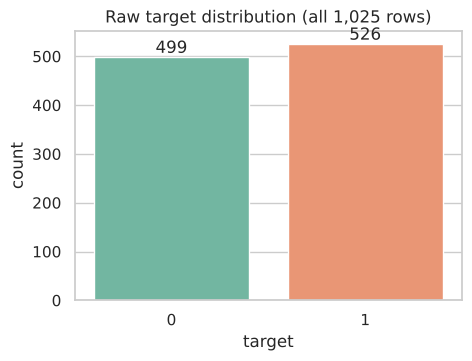

In [3]:
# Class distribution of the raw target column
counts = df_raw["target"].value_counts().sort_index()
pct = (df_raw["target"].value_counts(normalize=True).sort_index() * 100).round(1)
print(pd.DataFrame({"count": counts, "percent": pct}))

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df_raw, x="target", hue="target", palette="Set2", legend=False, ax=ax)
ax.set_title("Raw target distribution (all 1,025 rows)")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.show()

### Data-quality checks
Before modelling we look for problems that would silently distort the results: exact duplicate rows, impossible/placeholder codes and outliers.

In [4]:
# ---- Duplicates
n_dup = int(df_raw.duplicated().sum())
unique_rows = df_raw.drop_duplicates()
print(f"Exact duplicate rows : {n_dup} of {len(df_raw)} ({n_dup / len(df_raw):.1%})")
print(f"Unique rows          : {len(unique_rows)}")
conflicts = int(unique_rows.drop(columns="target").duplicated().sum())
print(f"Same features but different target among unique rows: {conflicts}")

# ---- Categorical value inventory (checks for impossible codes)
cat_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
print("\nUnique values per categorical column (unique rows only):")
for c in cat_cols:
    print(f"  {c:8s}", unique_rows[c].value_counts().sort_index().to_dict())

# ---- Numeric ranges
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
print("\nNumeric ranges:")
print(unique_rows[num_cols].agg(["min", "max", "mean", "median"]).T.round(2))
print("\nPlaceholder codes -> ca == 4:", int((unique_rows.ca == 4).sum()),
      "| thal == 0:", int((unique_rows.thal == 0).sum()))
print("Cholesterol > 400 mg/dl:", int((unique_rows.chol > 400).sum()),
      "| resting BP >= 180:", int((unique_rows.trestbps >= 180).sum()))

Exact duplicate rows : 723 of 1025 (70.5%)
Unique rows          : 302
Same features but different target among unique rows: 0

Unique values per categorical column (unique rows only):
  sex      {0: 96, 1: 206}
  cp       {0: 143, 1: 50, 2: 86, 3: 23}
  fbs      {0: 257, 1: 45}
  restecg  {0: 147, 1: 151, 2: 4}
  exang    {0: 203, 1: 99}
  slope    {0: 21, 1: 140, 2: 141}
  ca       {0: 175, 1: 65, 2: 38, 3: 20, 4: 4}
  thal     {0: 2, 1: 18, 2: 165, 3: 117}

Numeric ranges:
            min    max    mean  median
age        29.0   77.0   54.42    55.5
trestbps   94.0  200.0  131.60   130.0
chol      126.0  564.0  246.50   240.5
thalach    71.0  202.0  149.57   152.5
oldpeak     0.0    6.2    1.04     0.8

Placeholder codes -> ca == 4: 4 | thal == 0: 2
Cholesterol > 400 mg/dl: 4 | resting BP >= 180: 5


**Findings.**
1. **723 of the 1,025 rows are exact duplicates.** If left in, copies of the same patient would land in both the training and the test set and inflate every metric (a form of data leakage). We therefore work on the **unique rows only** in Task 2. No two unique rows share the same features with different labels.
2. `ca = 4` and `thal = 0` are not valid values of those clinical variables. They are the placeholders the original dataset used for *missing* values. We convert them to `NaN` and impute inside the pipeline (Task 2).
3. There are no true `NaN`s in the raw file, and the few extreme cholesterol / blood-pressure values are physiologically possible, so they are kept (tree-based models are robust to them and the other models use scaling).

### Verify the target encoding and category coding
The brief says `1 = heart disease`. Instead of trusting that, we check whether clinically known risk markers (exercise angina, ST depression `oldpeak`, number of blocked vessels `ca`, low peak heart rate `thalach`) go with `target = 1` or `target = 0`.

In [5]:
u = unique_rows.copy()

# Clinical direction: does the marker INCREASE (+1) or DECREASE (-1) when heart disease is present?
risk_markers = {"exang": +1, "oldpeak": +1, "ca": +1, "thalach": -1}
means = u.loc[u.ca != 4].groupby("target")[list(risk_markers)].mean().round(2)
print("Mean of each risk marker by raw target value:")
print(means.to_string(), "\n")

votes = {f: int(np.sign(means.loc[1, f] - means.loc[0, f]) * s) for f, s in risk_markers.items()}
print("Vote (+1 = 'target==1 looks like disease', -1 = 'target==0 looks like disease'):", votes)
DISEASE_CLASS = 1 if sum(votes.values()) > 0 else 0
print(f"\n=> In this file, raw target == {DISEASE_CLASS} corresponds to HEART DISEASE.")

print("\nUnique-row class counts      :", u.target.value_counts().sort_index().to_dict())
print("UCI Cleveland (303 patients) : 164 without disease, 139 with disease")
print("-> the 164-row class (target==1) matches the 'no disease' group.")

Mean of each risk marker by raw target value:
        exang  oldpeak    ca  thalach
target                               
0        0.55      1.6  1.15   139.07
1        0.14      0.6  0.27   158.31 

Vote (+1 = 'target==1 looks like disease', -1 = 'target==0 looks like disease'): {'exang': -1, 'oldpeak': -1, 'ca': -1, 'thalach': -1}

=> In this file, raw target == 0 corresponds to HEART DISEASE.

Unique-row class counts      : {0: 138, 1: 164}
UCI Cleveland (303 patients) : 164 without disease, 139 with disease
-> the 164-row class (target==1) matches the 'no disease' group.


In [6]:
# Category decoding: category frequencies and the share of target==0 (disease) per category.
# Counts are compared with the published Cleveland frequencies to decode the numeric codes.
for col, expected in {
    "cp":      "asymptomatic 144, atypical 50, non-anginal 86, typical 23",
    "restecg": "normal 151, ST-T abnormality 4, LVH 148",
    "slope":   "upsloping 142, flat 140, downsloping 21",
    "thal":    "normal 166, fixed defect 18, reversible defect 117 (2 missing)",
}.items():
    t = u.groupby(col).agg(n=("target", "size"), disease_rate=("target", lambda s: (s == DISEASE_CLASS).mean())).round(2)
    print(f"{col}  (Cleveland: {expected})")
    print(t.T.to_string(), "\n")

cp  (Cleveland: asymptomatic 144, atypical 50, non-anginal 86, typical 23)
cp                 0      1      2     3
n             143.00  50.00  86.00  23.0
disease_rate    0.73   0.18   0.21   0.3 

restecg  (Cleveland: normal 151, ST-T abnormality 4, LVH 148)
restecg            0       1     2
n             147.00  151.00  4.00
disease_rate    0.54    0.37  0.75 

slope  (Cleveland: upsloping 142, flat 140, downsloping 21)
slope             0       1       2
n             21.00  140.00  141.00
disease_rate   0.57    0.65    0.25 

thal  (Cleveland: normal 166, fixed defect 18, reversible defect 117 (2 missing))
thal            0      1       2       3
n             2.0  18.00  165.00  117.00
disease_rate  0.5   0.67    0.22    0.76 



**Decoding used in this project** (frequencies line up one-to-one with Cleveland, and the disease rates point the clinically expected way, e.g. asymptomatic chest pain = highest disease rate, upsloping ST = lowest):

- `cp`: 0 = asymptomatic (143), 1 = atypical angina (50), 2 = non-anginal pain (86), 3 = typical angina (23)
- `restecg`: 0 = LVH (147), 1 = normal (151), 2 = ST-T abnormality (4)
- `slope`: 0 = downsloping (21), 1 = flat (140), 2 = upsloping (141)
- `thal`: 1 = fixed defect (18), 2 = normal (165), 3 = reversible defect (117)

**Important:** `target == 1` in this file means **no heart disease**. That is the opposite of the notebook brief. We keep the original brief's convention for modelling by creating `HeartDisease = 1` when the patient has disease, so that recall means *"share of sick patients that we catch"*.

## Task 2: Data Preprocessing
- Handle missing values (if any): placeholder codes `ca == 4` and `thal == 0` become `NaN` and are imputed
- Encode categorical variables (`sex`, `cp`, `restecg`, `exang`, `slope`, `thal`, `fbs`, `ca`)
- Scale/normalize numerical features
- Check for class imbalance
- Split data into features (X) and target (y)

**Leakage policy.** Everything that *learns* from data (imputation values, scaling statistics, one-hot categories) lives inside a scikit-learn `Pipeline`/`ColumnTransformer`. It is fitted only on training folds and re-used unchanged at prediction time, so Flask applies exactly the same transformation.

In [7]:
# 1) Remove exact duplicates (see Task 1)
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f"Rows after removing duplicates: {len(df)} (removed {len(df_raw) - len(df)})")

# 2) Placeholder codes -> NaN. This uses no statistics from the data, so doing it before splitting is leak-free.
df["ca"] = df["ca"].replace(4, np.nan)
df["thal"] = df["thal"].replace(0, np.nan)
print("\nMissing values after cleaning:")
print(df.isnull().sum()[lambda s: s > 0].to_string())

# 3) Target: 1 = heart disease present (derived from the verified encoding of the raw column)
TARGET = "HeartDisease"
df[TARGET] = (df["target"] == DISEASE_CLASS).astype(int)
df = df.drop(columns="target")
TARGET_LABELS = {0: "No heart disease (lower likelihood)", 1: "Heart disease (higher likelihood)"}

# 4) Feature groups
FEATURES = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
            "thalach", "exang", "oldpeak", "slope", "ca", "thal"]
NUMERIC_FEATURES = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]   # ca = ordinal count 0-3 -> scaled
NOMINAL_FEATURES = ["cp", "restecg", "slope", "thal"]                          # unordered -> one-hot
BINARY_FEATURES  = ["sex", "fbs", "exang"]                                     # already 0/1 -> passthrough
assert sorted(NUMERIC_FEATURES + NOMINAL_FEATURES + BINARY_FEATURES) == sorted(FEATURES)

def build_preprocessor():
    """Fresh, unfitted preprocessing block: impute -> scale / one-hot / passthrough."""
    numeric = Pipeline([("imputer", SimpleImputer(strategy="median")),
                        ("scaler", StandardScaler())])
    nominal = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                        ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", numeric, NUMERIC_FEATURES),
                              ("cat", nominal, NOMINAL_FEATURES),
                              ("bin", "passthrough", BINARY_FEATURES)],
                             remainder="drop")

def build_pipeline(estimator):
    """Preprocessing + estimator as ONE object; this exact object is what gets saved and deployed."""
    return Pipeline([("preprocess", build_preprocessor()), ("model", estimator)])

# 5) Class imbalance check
cls = df[TARGET].value_counts().sort_index()
print("\nClass distribution (HeartDisease):")
print(pd.DataFrame({"count": cls, "percent": (cls / len(df) * 100).round(1)}).rename(index=TARGET_LABELS))
print(f"Imbalance ratio (majority/minority): {cls.max() / cls.min():.2f}")

# 6) Features / target
X = df[FEATURES].astype(float)
y = df[TARGET]
print("\nX shape:", X.shape, "| y shape:", y.shape)

Rows after removing duplicates: 302 (removed 723)

Missing values after cleaning:
ca      4
thal    2

Class distribution (HeartDisease):
                                     count  percent
HeartDisease                                       
No heart disease (lower likelihood)    164     54.3
Heart disease (higher likelihood)      138     45.7
Imbalance ratio (majority/minority): 1.19

X shape: (302, 13) | y shape: (302,)


**Decisions.**
- *Numeric (scaled):* `age`, `trestbps`, `chol`, `thalach`, `oldpeak`, and `ca` (an ordered count of vessels, 0-3). Scaling matters for KNN, SVM and Logistic Regression; trees ignore it but are not hurt by it.
- *Nominal (one-hot):* `cp`, `restecg`, `slope`, `thal` - their numeric codes have no meaningful order.
- *Binary (passthrough):* `sex`, `fbs`, `exang`.
- *Imbalance:* the classes are close to balanced (ratio about 1.2), so no resampling or class weights are needed. We still use **stratified** splits so each fold keeps the class ratio.

## Task 3: Exploratory Data Analysis (EDA)
- Plot correlation matrix heatmap
- Create distribution plots for numerical features
- Visualize relationships between features and target
- Create pairplots for selected features

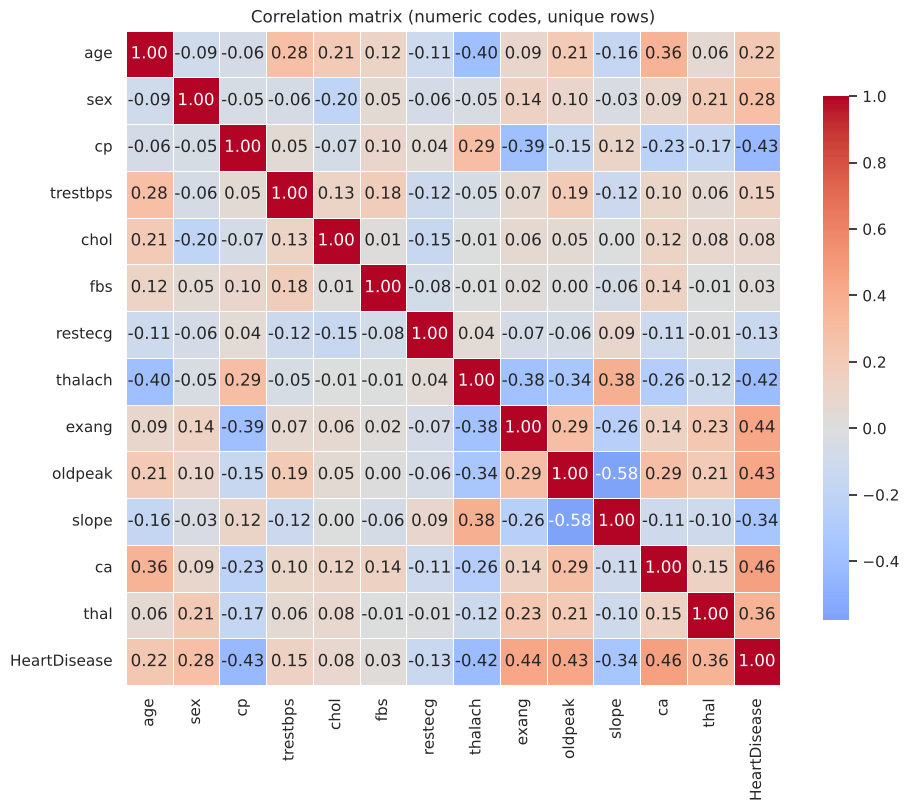

Strongest correlations with HeartDisease:
ca         0.464
exang      0.436
cp        -0.432
oldpeak    0.429
thalach   -0.420
thal       0.364


In [8]:
# Readable copy for plotting only (not used for modelling)
CATEGORY_LABELS = {
    "sex":     {0: "Female", 1: "Male"},
    "cp":      {0: "Asymptomatic", 1: "Atypical angina", 2: "Non-anginal", 3: "Typical angina"},
    "fbs":     {0: "<= 120 mg/dl", 1: "> 120 mg/dl"},
    "restecg": {0: "LVH", 1: "Normal", 2: "ST-T abnormality"},
    "exang":   {0: "No", 1: "Yes"},
    "slope":   {0: "Downsloping", 1: "Flat", 2: "Upsloping"},
    "ca":      {0.0: "0", 1.0: "1", 2.0: "2", 3.0: "3"},
    "thal":    {1.0: "Fixed defect", 2.0: "Normal", 3.0: "Reversible defect"},
}
plot_df = df.copy()
plot_df["Status"] = plot_df[TARGET].map({0: "No disease", 1: "Disease"})
for col, mapping in CATEGORY_LABELS.items():
    plot_df[col] = plot_df[col].map(mapping)
STATUS_PALETTE = {"No disease": "#2a9d8f", "Disease": "#e76f51"}

# ---- Correlation heatmap
corr = df[FEATURES + [TARGET]].corr()
plt.figure(figsize=(11, 8.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5, square=True,
            cbar_kws={"shrink": 0.8})
plt.title("Correlation matrix (numeric codes, unique rows)")
save_fig("correlation_heatmap.png")
plt.show()

print("Strongest correlations with HeartDisease:")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).head(6).round(3).to_string())

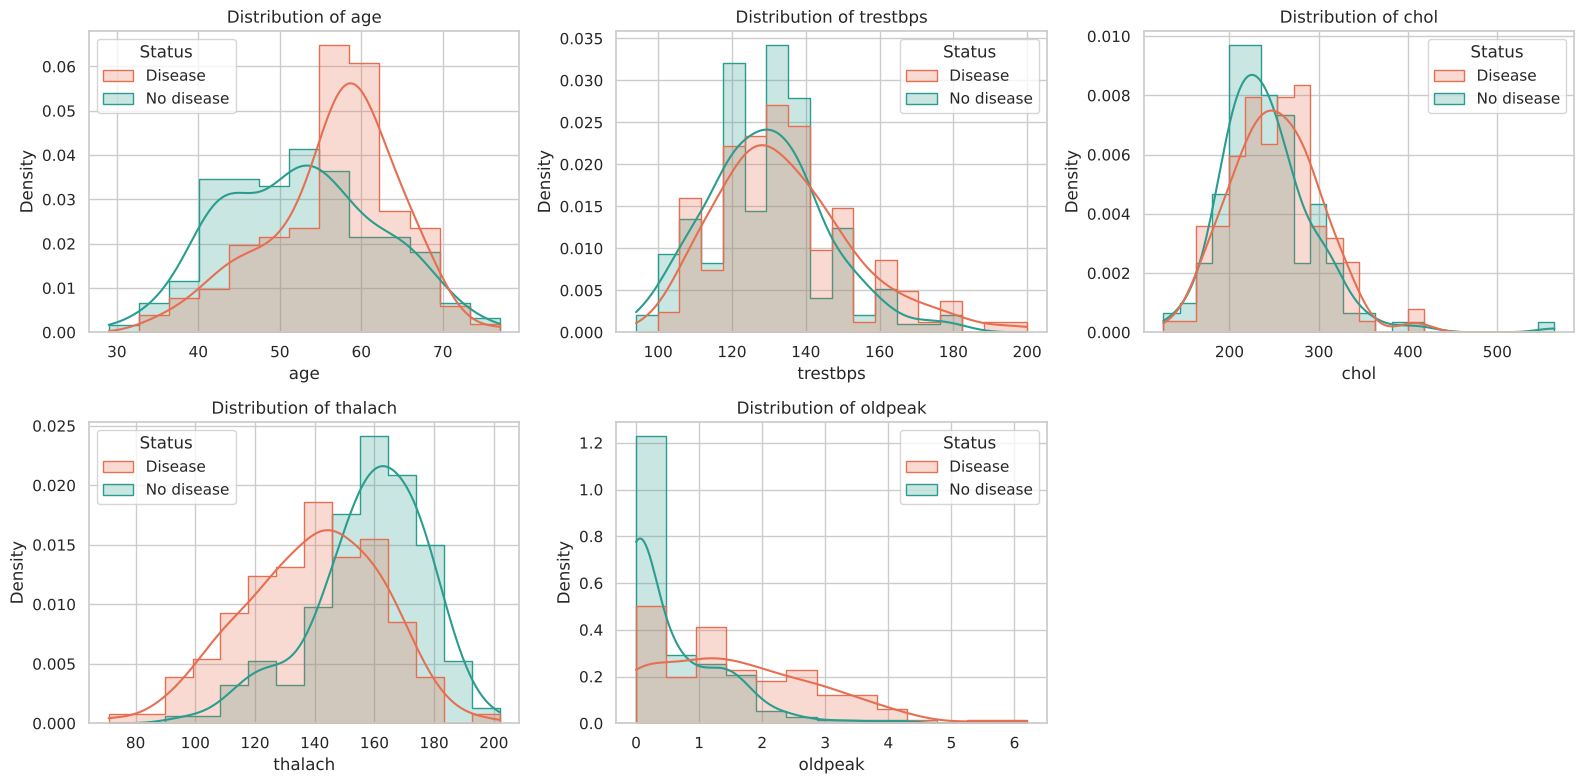

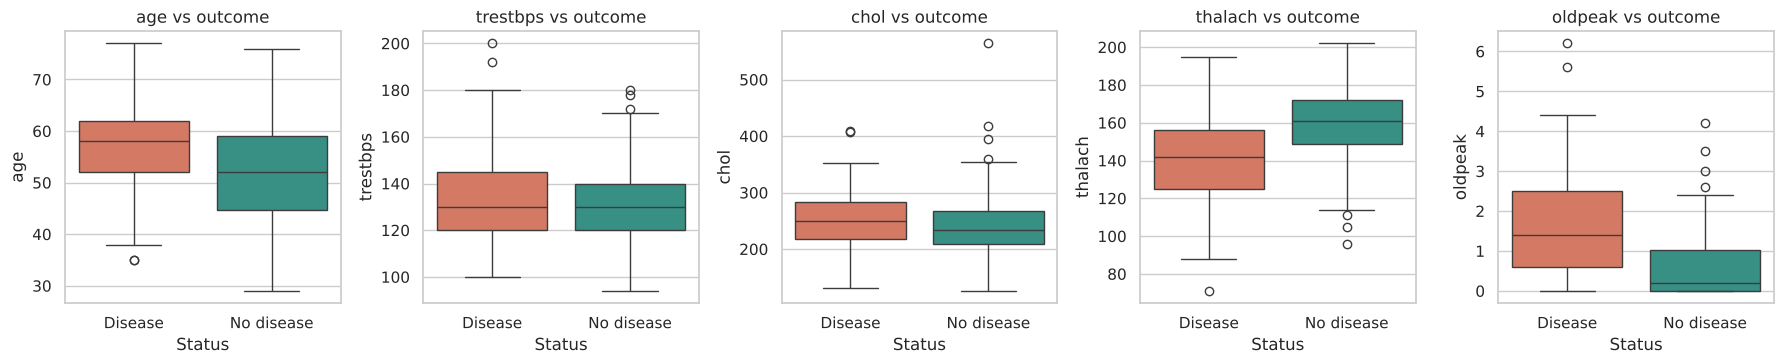

In [9]:
# ---- Distributions of continuous features, split by outcome
cont = ["age", "trestbps", "chol", "thalach", "oldpeak"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), cont):
    sns.histplot(data=plot_df, x=col, hue="Status", kde=True, palette=STATUS_PALETTE,
                 element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(f"Distribution of {col}")
axes.ravel()[-1].axis("off")
plt.tight_layout()
save_fig("numeric_distributions.png")
plt.show()

# ---- Boxplots: continuous feature vs outcome
fig, axes = plt.subplots(1, 5, figsize=(18, 3.8))
for ax, col in zip(axes, cont):
    sns.boxplot(data=plot_df, x="Status", y=col, hue="Status", palette=STATUS_PALETTE, legend=False, ax=ax)
    ax.set_title(f"{col} vs outcome")
plt.tight_layout()
plt.show()

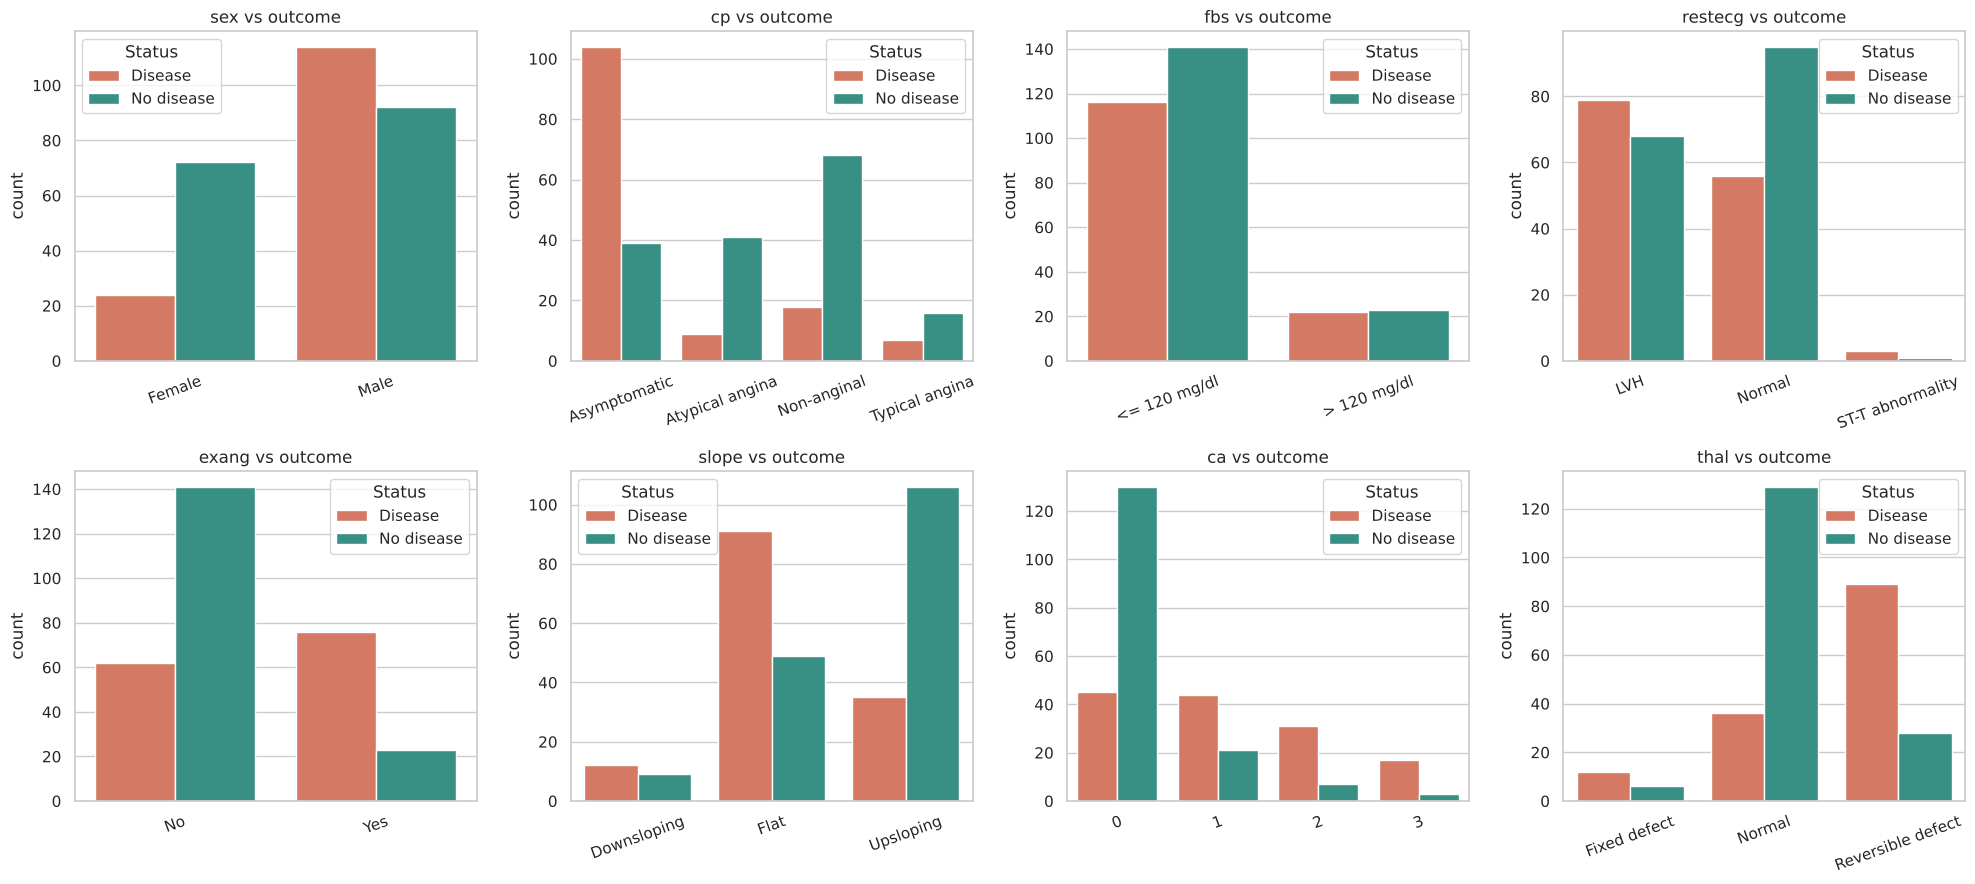

sex      disease rate: {'Female': 0.25, 'Male': 0.55}
cp       disease rate: {'Asymptomatic': 0.73, 'Atypical angina': 0.18, 'Non-anginal': 0.21, 'Typical angina': 0.3}
fbs      disease rate: {'<= 120 mg/dl': 0.45, '> 120 mg/dl': 0.49}
restecg  disease rate: {'LVH': 0.54, 'Normal': 0.37, 'ST-T abnormality': 0.75}
exang    disease rate: {'No': 0.31, 'Yes': 0.77}
slope    disease rate: {'Downsloping': 0.57, 'Flat': 0.65, 'Upsloping': 0.25}
ca       disease rate: {'0': 0.26, '1': 0.68, '2': 0.82, '3': 0.85}
thal     disease rate: {'Fixed defect': 0.67, 'Normal': 0.22, 'Reversible defect': 0.76}


In [10]:
# ---- Categorical features vs outcome (counts)
cat_plot = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.ravel(), cat_plot):
    order = [v for v in CATEGORY_LABELS[col].values() if v in set(plot_df[col].dropna())]
    sns.countplot(data=plot_df, x=col, hue="Status", order=order, palette=STATUS_PALETTE, ax=ax)
    ax.set_title(f"{col} vs outcome")
    ax.tick_params(axis="x", rotation=20)
    ax.set_xlabel("")
plt.tight_layout()
save_fig("categorical_vs_target.png")
plt.show()

# Disease rate per category (quantifies the plots above)
rates = {c: (plot_df.groupby(c)[TARGET].mean().round(2)).to_dict() for c in cat_plot}
for c, r in rates.items():
    print(f"{c:8s} disease rate:", r)

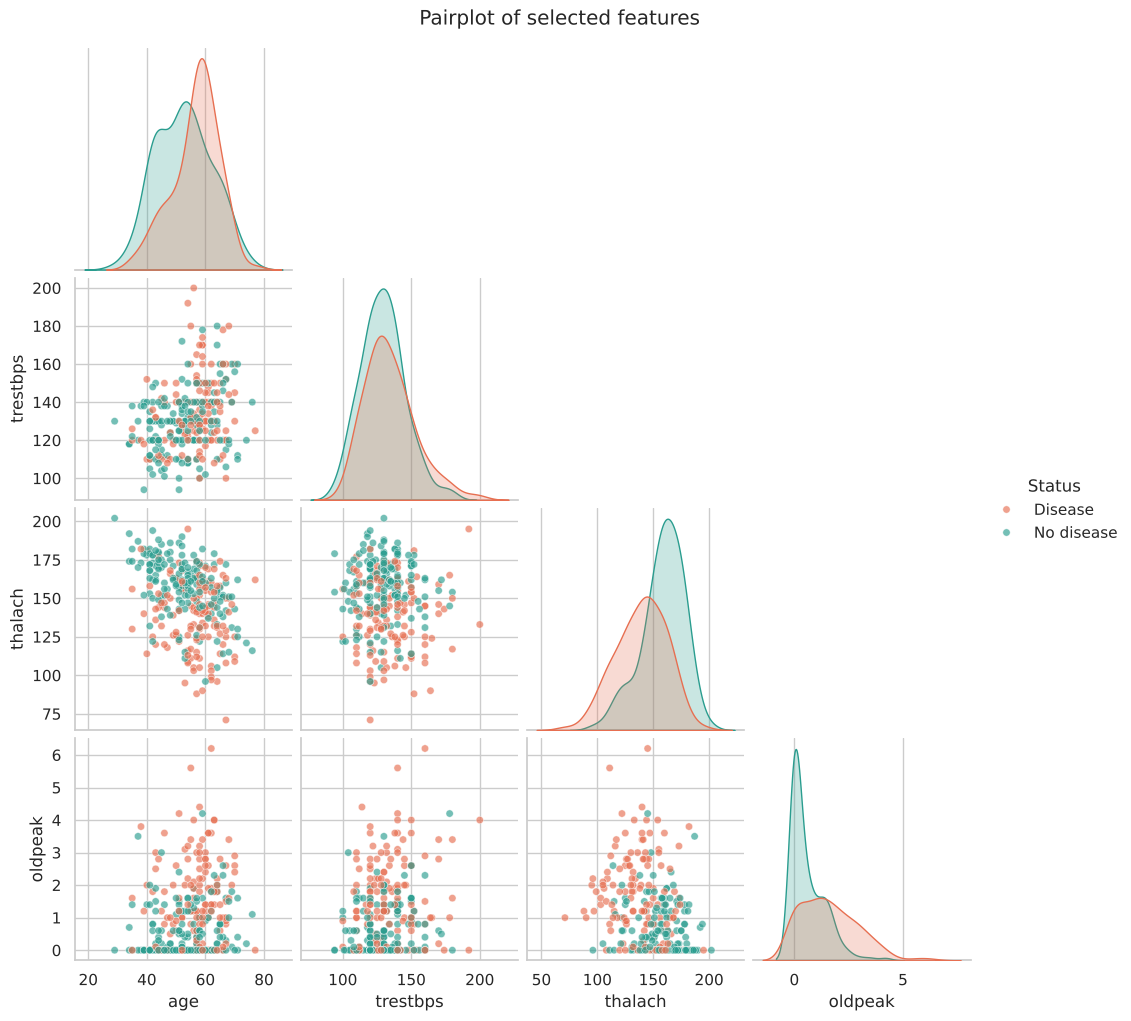

In [11]:
# ---- Pairplot for selected continuous features
sel = ["age", "trestbps", "thalach", "oldpeak"]
g = sns.pairplot(plot_df[sel + ["Status"]], hue="Status", palette=STATUS_PALETTE,
                 corner=True, plot_kws={"alpha": 0.65, "s": 28}, diag_kind="kde")
g.figure.suptitle("Pairplot of selected features", y=1.02)
save_fig("pairplot.png")
plt.show()

**EDA takeaways** (all read from the plots/tables above):
- The features most associated with disease are exercise-induced angina, ST depression (`oldpeak`), number of coloured vessels (`ca`), asymptomatic chest pain, a reversible thal defect and a flat/down ST slope, while a high maximum heart rate (`thalach`) goes with *no* disease.
- `age`, `trestbps`, `chol` and `fbs` separate the groups only weakly.
- The pairplot shows overlapping but visibly shifted clouds (e.g. `thalach` vs `oldpeak`), so a good but not perfect classification is expected, and several features carry complementary signal.

## Task 4: Data Splitting and Cross-Validation Setup
- Split data into training (80%) and testing (20%) sets
- Implement K-Fold cross-validation (k=5 or k=10)
- Explain the purpose of cross-validation in reducing overfitting

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")
print("Disease share  -> full: {:.3f} | train: {:.3f} | test: {:.3f}".format(y.mean(), y_train.mean(), y_test.mean()))

# 5-fold stratified CV, shuffled with a fixed seed. Used for tuning and training-time evaluation.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for i, (tr, va) in enumerate(cv.split(X_train, y_train), 1):
    print(f"Fold {i}: train={len(tr)}  validation={len(va)}  disease share in validation={y_train.iloc[va].mean():.3f}")

# Demonstration: preprocessing is fitted on the TRAINING data only
demo = build_preprocessor().fit(X_train)
Xt = demo.transform(X_train)
print("\nTransformed training matrix:", Xt.shape)
print("Output features:", list(demo.get_feature_names_out()))

Train: 241 rows | Test: 61 rows
Disease share  -> full: 0.457 | train: 0.456 | test: 0.459
Fold 1: train=192  validation=49  disease share in validation=0.449
Fold 2: train=193  validation=48  disease share in validation=0.458
Fold 3: train=193  validation=48  disease share in validation=0.458
Fold 4: train=193  validation=48  disease share in validation=0.458
Fold 5: train=193  validation=48  disease share in validation=0.458

Transformed training matrix: (241, 22)
Output features: ['num__age', 'num__trestbps', 'num__chol', 'num__thalach', 'num__oldpeak', 'num__ca', 'cat__cp_0.0', 'cat__cp_1.0', 'cat__cp_2.0', 'cat__cp_3.0', 'cat__restecg_0.0', 'cat__restecg_1.0', 'cat__restecg_2.0', 'cat__slope_0.0', 'cat__slope_1.0', 'cat__slope_2.0', 'cat__thal_1.0', 'cat__thal_2.0', 'cat__thal_3.0', 'bin__sex', 'bin__fbs', 'bin__exang']


### Why cross-validation reduces overfitting
A model scored on the same data it was trained on looks better than it is, because it can memorise noise. **K-fold cross-validation** splits the training set into *k* parts, trains on *k-1* of them and scores on the held-out part, rotating until every row has served as validation data once. This gives:

1. **An honest performance estimate** - every score comes from rows the model did not see while fitting.
2. **A variance estimate** - the spread across folds shows how sensitive the model is to the particular training sample.
3. **A safe way to tune hyperparameters** - we pick settings that generalise across folds instead of ones that merely fit one split, which discourages over-complex models.

We use `StratifiedKFold` so every fold keeps the original class ratio, and the **20% test set is never touched during tuning**: it is used once, at the end, as an unbiased check.

## Task 5: Model Implementation and Training
Implement and compare the following algorithms:
1. K-Nearest Neighbors (KNN)
2. Logistic Regression
3. Decision Tree Classifier
4. Random Forest Classifier
5. Support Vector Machine (SVM)

For each algorithm:
- Initialize the model with appropriate parameters
- Train using cross-validation
- Perform hyperparameter tuning

In [13]:
# Shared helper: baseline CV score -> GridSearchCV (5-fold stratified) -> summary
# zero_division=0: a degenerate configuration that predicts no positives gets precision 0 instead of a warning
SCORING = {"roc_auc": "roc_auc", "accuracy": "accuracy",
           "f1": make_scorer(f1_score, zero_division=0),
           "recall": make_scorer(recall_score, zero_division=0),
           "precision": make_scorer(precision_score, zero_division=0)}
tuned = {}          # name -> fitted GridSearchCV (best_estimator_ is a full preprocessing+model Pipeline)
tuning_rows = []

def _prefix(grid):
    if isinstance(grid, list):
        return [_prefix(g) for g in grid]
    return {f"model__{k}": v for k, v in grid.items()}

def tune_and_report(name, estimator, grid):
    pipe = build_pipeline(estimator)
    base = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=N_JOBS)
    gs = GridSearchCV(pipe, _prefix(grid), scoring=SCORING, refit="roc_auc",
                      cv=cv, n_jobs=N_JOBS)
    gs.fit(X_train, y_train)
    i = gs.best_index_
    res = gs.cv_results_
    row = {"Model": name,
           "Baseline CV ROC-AUC": base["test_roc_auc"].mean(),
           "Tuned CV ROC-AUC": res["mean_test_roc_auc"][i],
           "Tuned CV F1": res["mean_test_f1"][i],
           "Tuned CV Recall": res["mean_test_recall"][i],
           "Tuned CV Accuracy": res["mean_test_accuracy"][i],
           "Configs x folds": len(res["params"]) * cv.get_n_splits()}
    tuned[name] = gs
    tuning_rows.append(row)

    print(f"=== {name} ===")
    print("Baseline (initial params) 5-fold ROC-AUC: {:.3f} +/- {:.3f}".format(
        base["test_roc_auc"].mean(), base["test_roc_auc"].std()))
    print("Best params:", {k.replace("model__", ""): (v.item() if hasattr(v, "item") else v) for k, v in gs.best_params_.items()})
    print("Tuned 5-fold ROC-AUC per fold:", [round(float(res[f"split{k}_test_roc_auc"][i]), 3) for k in range(cv.get_n_splits())])
    print("Tuned CV  ROC-AUC {:.3f} | F1 {:.3f} | Recall {:.3f} | Precision {:.3f} | Accuracy {:.3f}".format(
        res["mean_test_roc_auc"][i], res["mean_test_f1"][i], res["mean_test_recall"][i],
        res["mean_test_precision"][i], res["mean_test_accuracy"][i]))
    return gs

### 5.1 K-Nearest Neighbors (KNN)
Distance-based, so the scaling in the pipeline is essential. Tuned: number of neighbours, vote weighting, distance metric (p=1 Manhattan, p=2 Euclidean).

In [14]:
knn_gs = tune_and_report(
    "KNN",
    KNeighborsClassifier(n_neighbors=5),
    {"n_neighbors": list(range(3, 28, 2)), "weights": ["uniform", "distance"], "p": [1, 2]})

=== KNN ===
Baseline (initial params) 5-fold ROC-AUC: 0.883 +/- 0.027
Best params: {'n_neighbors': 21, 'p': 1, 'weights': 'distance'}
Tuned 5-fold ROC-AUC per fold: [0.955, 0.934, 0.892, 0.925, 0.866]
Tuned CV  ROC-AUC 0.914 | F1 0.787 | Recall 0.727 | Precision 0.868 | Accuracy 0.821


### 5.2 Logistic Regression
Linear, interpretable baseline. Tuned: inverse regularisation strength `C` and the penalty type via `l1_ratio` (0.0 = L2 / ridge, 1.0 = L1 / lasso; `liblinear` supports both).

In [15]:
lr_gs = tune_and_report(
    "Logistic Regression",
    LogisticRegression(solver="liblinear", max_iter=5000, random_state=RANDOM_STATE),
    {"C": list(np.logspace(-3, 2, 11)), "l1_ratio": [0.0, 1.0]})   # 0.0 = L2 penalty, 1.0 = L1 penalty

=== Logistic Regression ===
Baseline (initial params) 5-fold ROC-AUC: 0.913 +/- 0.028
Best params: {'C': 0.31622776601683794, 'l1_ratio': 0.0}
Tuned 5-fold ROC-AUC per fold: [0.968, 0.914, 0.888, 0.911, 0.892]
Tuned CV  ROC-AUC 0.915 | F1 0.836 | Recall 0.800 | Precision 0.882 | Accuracy 0.859


### 5.3 Decision Tree Classifier
Highly interpretable but prone to overfitting, so depth and leaf size are the key tuned parameters.

In [16]:
dt_gs = tune_and_report(
    "Decision Tree",
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    {"max_depth": [2, 3, 4, 5, 6, 8, None], "min_samples_leaf": [1, 2, 5, 10], "criterion": ["gini", "entropy"]})

=== Decision Tree ===
Baseline (initial params) 5-fold ROC-AUC: 0.752 +/- 0.055
Best params: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 10}
Tuned 5-fold ROC-AUC per fold: [0.908, 0.856, 0.835, 0.874, 0.879]
Tuned CV  ROC-AUC 0.870 | F1 0.765 | Recall 0.682 | Precision 0.877 | Accuracy 0.809


### 5.4 Random Forest Classifier
Ensemble of decorrelated trees that reduces the variance of a single tree. Tuned: number of trees, depth, leaf size and features per split.

In [17]:
rf_gs = tune_and_report(
    "Random Forest",
    RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1),
    {"n_estimators": [100, 300], "max_depth": [None, 3, 5, 8],
     "min_samples_leaf": [1, 2, 4], "max_features": ["sqrt", "log2"]})

=== Random Forest ===
Baseline (initial params) 5-fold ROC-AUC: 0.907 +/- 0.027
Best params: {'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 100}
Tuned 5-fold ROC-AUC per fold: [0.968, 0.928, 0.892, 0.928, 0.9]
Tuned CV  ROC-AUC 0.923 | F1 0.818 | Recall 0.782 | Precision 0.864 | Accuracy 0.842


### 5.5 Support Vector Machine (SVM)
Margin-based; `probability=True` is enabled so ROC curves and the Flask app can use class probabilities. Tuned: kernel, `C`, and `gamma` for the RBF kernel.

In [18]:
svm_gs = tune_and_report(
    "SVM",
    SVC(probability=True, random_state=RANDOM_STATE),
    [{"kernel": ["rbf"], "C": [0.1, 0.5, 1, 5, 10], "gamma": ["scale", 0.01, 0.05, 0.1]},
     {"kernel": ["linear"], "C": [0.01, 0.1, 1, 10]}])

=== SVM ===
Baseline (initial params) 5-fold ROC-AUC: 0.904 +/- 0.021
Best params: {'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}
Tuned 5-fold ROC-AUC per fold: [0.96, 0.916, 0.897, 0.928, 0.874]
Tuned CV  ROC-AUC 0.915 | F1 0.823 | Recall 0.745 | Precision 0.927 | Accuracy 0.855


In [19]:
# Side-by-side view of the tuning effect (cross-validation on the training set only)
tuning_summary = pd.DataFrame(tuning_rows).set_index("Model").round(3)
tuning_summary

,Baseline CV ROC-AUC,Tuned CV ROC-AUC,Tuned CV F1,Tuned CV Recall,Tuned CV Accuracy,Configs x folds
Model,,,,,,
KNN,0.883,0.914,0.787,0.727,0.821,260
Logistic Regression,0.913,0.915,0.836,0.800,0.859,110
Decision Tree,0.752,0.870,0.765,0.682,0.809,280
Random Forest,0.907,0.923,0.818,0.782,0.842,240
SVM,0.904,0.915,0.823,0.745,0.855,120


## Task 6: Model Evaluation
For each trained model, calculate and compare:
- Accuracy, Precision, Recall, and F1-score
- Generate confusion matrices
- Plot ROC curves and calculate AUC scores
- Analyze bias-variance tradeoff using learning curves

All five tuned models are scored on the **same untouched 20% test set**. *Positive class = heart disease* (`HeartDisease = 1`), so **recall = sensitivity** (share of sick patients identified) and **precision** = share of positive alarms that are real.

In [20]:
def evaluate_on_test(name, est):
    pred = est.predict(X_test)
    proba = est.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"Model": name,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred),
            "Recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred),
            "ROC-AUC": roc_auc_score(y_test, proba),
            "Specificity": tn / (tn + fp),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}

test_results = pd.DataFrame([evaluate_on_test(n, gs.best_estimator_) for n, gs in tuned.items()]).set_index("Model")
print(f"Hold-out test set: {len(y_test)} patients ({int(y_test.sum())} with disease)\n")
test_results.round(3)

Hold-out test set: 61 patients (28 with disease)



,Accuracy,Precision,Recall,F1,ROC-AUC,Specificity,TN,FP,FN,TP
Model,,,,,,,,,,
KNN,0.820,0.815,0.786,0.800,0.897,0.848,28,5,6,22
Logistic Regression,0.836,0.875,0.750,0.808,0.906,0.909,30,3,7,21
Decision Tree,0.770,0.750,0.750,0.750,0.851,0.788,26,7,7,21
Random Forest,0.787,0.800,0.714,0.755,0.905,0.848,28,5,8,20
SVM,0.836,0.875,0.750,0.808,0.906,0.909,30,3,7,21


In [21]:
for name, gs in tuned.items():
    print(f"----- {name} -----")
    print(classification_report(y_test, gs.best_estimator_.predict(X_test),
                                target_names=["No disease", "Disease"], digits=3))

----- KNN -----
              precision    recall  f1-score   support

  No disease      0.824     0.848     0.836        33
     Disease      0.815     0.786     0.800        28

    accuracy                          0.820        61
   macro avg      0.819     0.817     0.818        61
weighted avg      0.820     0.820     0.819        61

----- Logistic Regression -----
              precision    recall  f1-score   support

  No disease      0.811     0.909     0.857        33
     Disease      0.875     0.750     0.808        28

    accuracy                          0.836        61
   macro avg      0.843     0.830     0.832        61
weighted avg      0.840     0.836     0.834        61

----- Decision Tree -----
              precision    recall  f1-score   support

  No disease      0.788     0.788     0.788        33
     Disease      0.750     0.750     0.750        28

    accuracy                          0.770        61
   macro avg      0.769     0.769     0.769        61


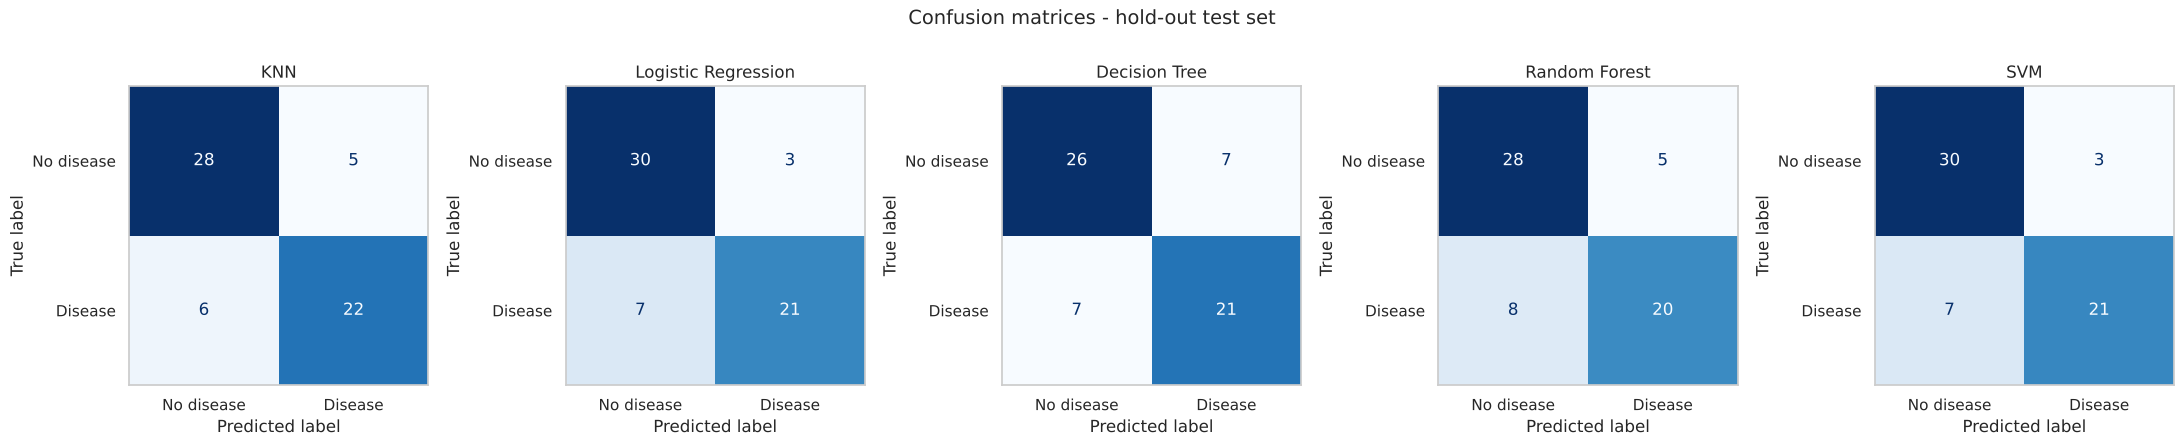

In [22]:
# ---- Confusion matrices
fig, axes = plt.subplots(1, 5, figsize=(22, 4.2))
for ax, (name, gs) in zip(axes, tuned.items()):
    ConfusionMatrixDisplay.from_estimator(gs.best_estimator_, X_test, y_test,
                                          display_labels=["No disease", "Disease"],
                                          cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
    ax.grid(False)
plt.suptitle("Confusion matrices - hold-out test set", y=1.03, fontsize=14)
plt.tight_layout()
save_fig("confusion_matrices.png")
plt.show()

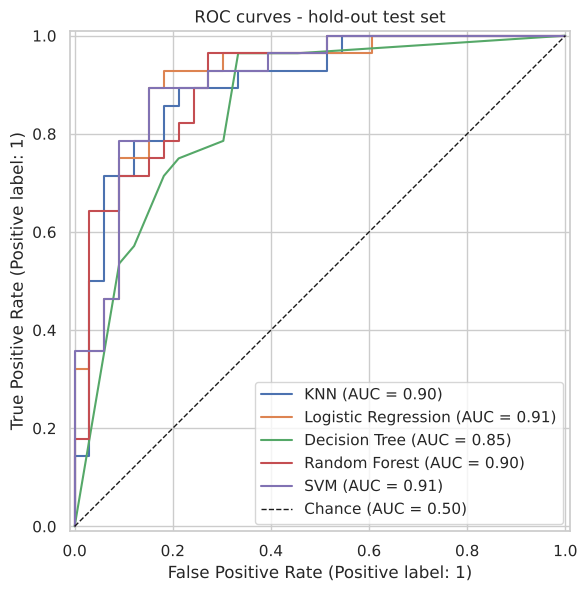

ROC-AUC (test):
Model
Logistic Regression    0.906
SVM                    0.906
Random Forest          0.905
KNN                    0.897
Decision Tree          0.851


In [23]:
# ---- ROC curves (all models, test set)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
for name, gs in tuned.items():
    RocCurveDisplay.from_estimator(gs.best_estimator_, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance (AUC = 0.50)")
ax.set_title("ROC curves - hold-out test set")
ax.legend(loc="lower right")
save_fig("roc_curves.png")
plt.show()

print("ROC-AUC (test):")
print(test_results["ROC-AUC"].round(3).sort_values(ascending=False).to_string())

### Bias-variance trade-off and learning curves
A learning curve trains the model on growing fractions of the training set and plots the training score and the cross-validated score:
- **High bias (underfitting):** both curves converge at a *low* score - the model is too simple, more data will not help.
- **High variance (overfitting):** training score stays far above the validation score - the model memorises; regularisation or more data helps.

The diagnosis below uses simple heuristics on the last point of each curve (gap >= 0.10 -> high variance; validation accuracy < 0.78 with a small gap -> high bias).

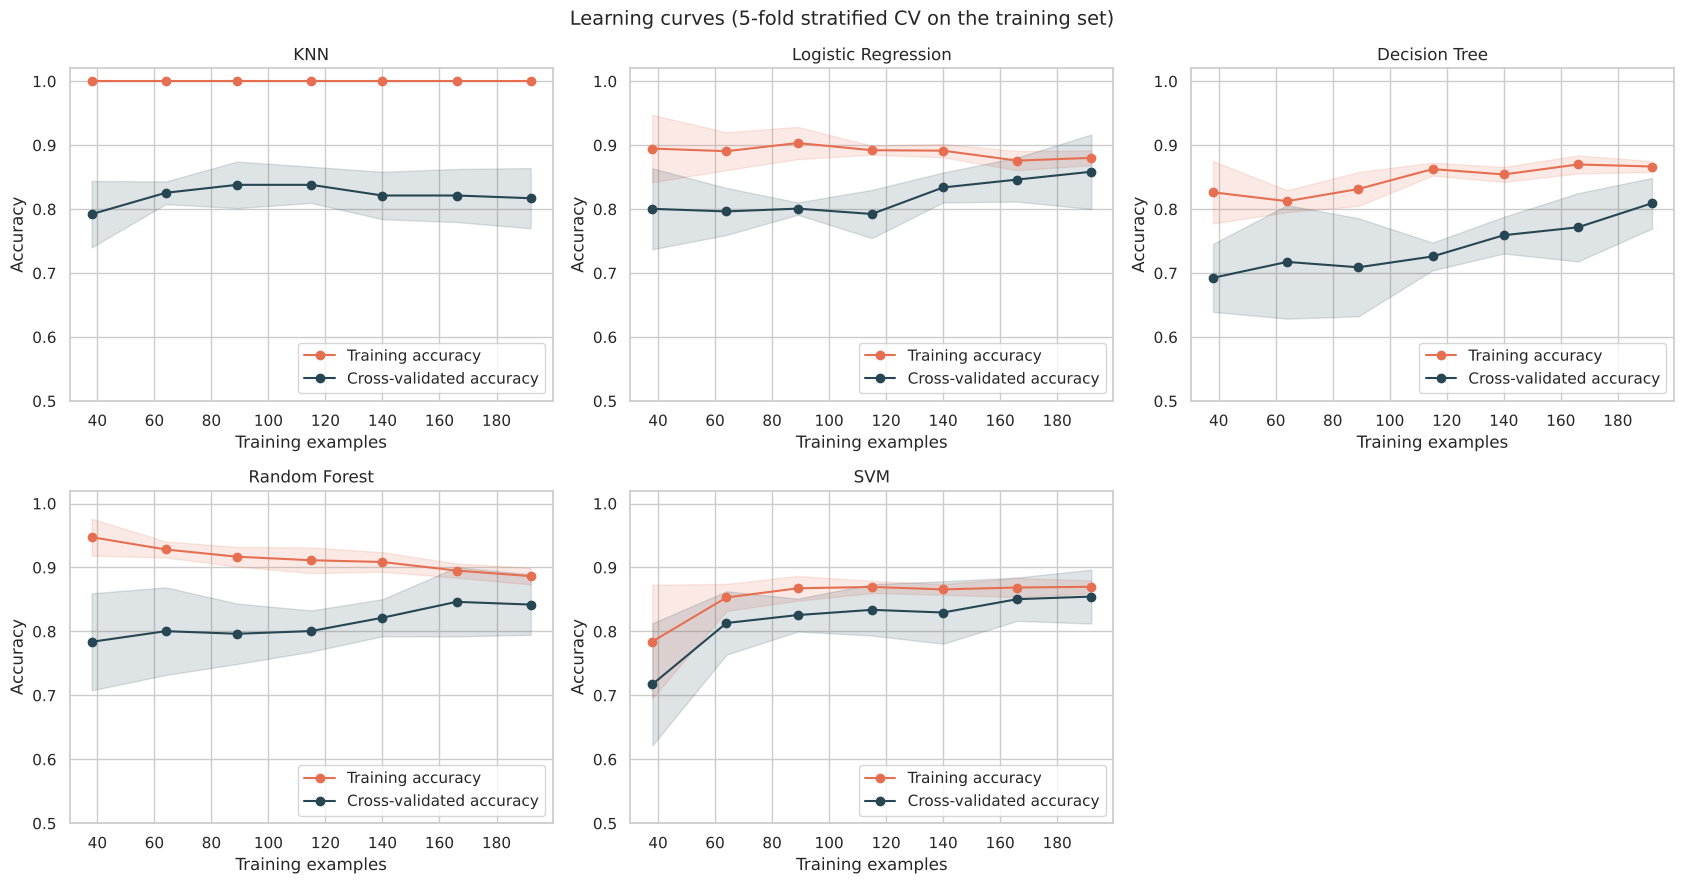

,Train acc,CV acc,Gap,CV acc still rising?,Diagnosis
Model,,,,,
KNN,1.000,0.817,0.183,False,High variance (overfitting)
Logistic Regression,0.880,0.859,0.022,True,Reasonably balanced
Decision Tree,0.867,0.809,0.057,True,Reasonably balanced
Random Forest,0.886,0.842,0.044,True,Reasonably balanced
SVM,0.870,0.855,0.015,True,Reasonably balanced


In [24]:
sizes = np.linspace(0.2, 1.0, 7)
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
axes = axes.ravel()
lc_rows = []

for ax, (name, gs) in zip(axes, tuned.items()):
    ts, tr, va = learning_curve(clone(gs.best_estimator_), X_train, y_train, cv=cv,
                                train_sizes=sizes, scoring="accuracy",
                                n_jobs=N_JOBS, shuffle=True, random_state=RANDOM_STATE)
    tr_m, tr_s, va_m, va_s = tr.mean(1), tr.std(1), va.mean(1), va.std(1)
    ax.plot(ts, tr_m, "o-", color="#e76f51", label="Training accuracy")
    ax.fill_between(ts, tr_m - tr_s, tr_m + tr_s, color="#e76f51", alpha=0.15)
    ax.plot(ts, va_m, "o-", color="#264653", label="Cross-validated accuracy")
    ax.fill_between(ts, va_m - va_s, va_m + va_s, color="#264653", alpha=0.15)
    ax.set_title(name)
    ax.set_xlabel("Training examples")
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0.5, 1.02)
    ax.legend(loc="lower right")

    gap = tr_m[-1] - va_m[-1]
    if gap >= 0.10:
        verdict = "High variance (overfitting)"
    elif va_m[-1] < 0.78:
        verdict = "High bias (underfitting)"
    else:
        verdict = "Reasonably balanced"
    lc_rows.append({"Model": name, "Train acc": tr_m[-1], "CV acc": va_m[-1], "Gap": gap,
                    "CV acc still rising?": (va_m[-1] - va_m[-3]) > 0.01, "Diagnosis": verdict})

axes[-1].axis("off")
plt.suptitle("Learning curves (5-fold stratified CV on the training set)", fontsize=14)
plt.tight_layout()
save_fig("learning_curves.png")
plt.show()

bias_variance = pd.DataFrame(lc_rows).set_index("Model")
bias_variance.round(3)

In [25]:
# Plain-language reading of the table above, generated from the measured numbers
for name, r in bias_variance.iterrows():
    msg = (f"- {name}: train {r['Train acc']:.3f} vs CV {r['CV acc']:.3f} (gap {r['Gap']:.3f}) -> {r['Diagnosis']}"
           + ("; validation score still improving, more data would likely help." if r["CV acc still rising?"] else "."))
    print(msg)

- KNN: train 1.000 vs CV 0.817 (gap 0.183) -> High variance (overfitting).
- Logistic Regression: train 0.880 vs CV 0.859 (gap 0.022) -> Reasonably balanced; validation score still improving, more data would likely help.
- Decision Tree: train 0.867 vs CV 0.809 (gap 0.057) -> Reasonably balanced; validation score still improving, more data would likely help.
- Random Forest: train 0.886 vs CV 0.842 (gap 0.044) -> Reasonably balanced; validation score still improving, more data would likely help.
- SVM: train 0.870 vs CV 0.855 (gap 0.015) -> Reasonably balanced; validation score still improving, more data would likely help.


## Task 7: Comprehensive Model Comparison
- Create comparison table of all models' performance metrics
- Visualize performance comparison using bar charts
- Identify the best performing model based on multiple criteria
- Discuss trade-offs between different evaluation metrics

**Method.** The test set has only 61 patients (one patient = 1.6 percentage points), so choosing the winner on it alone would be noisy and would also "use up" the hold-out data. We therefore:
1. Evaluate every tuned model with the **same repeated stratified 5-fold CV (3 repeats, a different seed than the tuning CV) on the training set** - this is the basis for model *selection*.
2. Report the **hold-out test metrics** (Task 6) as the final, independent confirmation of the selected model.

Every model is therefore judged by the same procedure on the same data.

In [26]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=2024)
CV_SCORING = {**SCORING, "balanced_accuracy": "balanced_accuracy"}

cv_rows = []
for name, gs in tuned.items():
    r = cross_validate(clone(gs.best_estimator_), X_train, y_train, cv=rcv, scoring=CV_SCORING,
                       return_train_score=True, n_jobs=N_JOBS)
    cv_rows.append({"Model": name,
                    "Accuracy": r["test_accuracy"].mean(),
                    "Precision": r["test_precision"].mean(),
                    "Recall": r["test_recall"].mean(),
                    "F1": r["test_f1"].mean(),
                    "ROC-AUC": r["test_roc_auc"].mean(),
                    "Balanced Acc": r["test_balanced_accuracy"].mean(),
                    "ROC-AUC std": r["test_roc_auc"].std(),
                    "Train-CV AUC gap": r["train_roc_auc"].mean() - r["test_roc_auc"].mean()})
cv_table = pd.DataFrame(cv_rows).set_index("Model")

print("A) Repeated 5-fold CV on the training set (15 folds per model) - basis for selection")
display(cv_table.round(3))
print("\nB) Hold-out test set (61 patients) - independent confirmation")
display(test_results[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "Specificity"]].round(3))

A) Repeated 5-fold CV on the training set (15 folds per model) - basis for selection


,Accuracy,Precision,Recall,F1,ROC-AUC,Balanced Acc,ROC-AUC std,Train-CV AUC gap
Model,,,,,,,,
KNN,0.841,0.884,0.755,0.810,0.912,0.834,0.043,0.088
Logistic Regression,0.862,0.880,0.812,0.841,0.918,0.858,0.042,0.024
Decision Tree,0.828,0.860,0.748,0.798,0.857,0.822,0.073,0.066
Random Forest,0.848,0.864,0.797,0.824,0.920,0.844,0.039,0.042
SVM,0.848,0.899,0.755,0.817,0.917,0.840,0.043,0.018



B) Hold-out test set (61 patients) - independent confirmation


,Accuracy,Precision,Recall,F1,ROC-AUC,Specificity
Model,,,,,,
KNN,0.820,0.815,0.786,0.800,0.897,0.848
Logistic Regression,0.836,0.875,0.750,0.808,0.906,0.909
Decision Tree,0.770,0.750,0.750,0.750,0.851,0.788
Random Forest,0.787,0.800,0.714,0.755,0.905,0.848
SVM,0.836,0.875,0.750,0.808,0.906,0.909


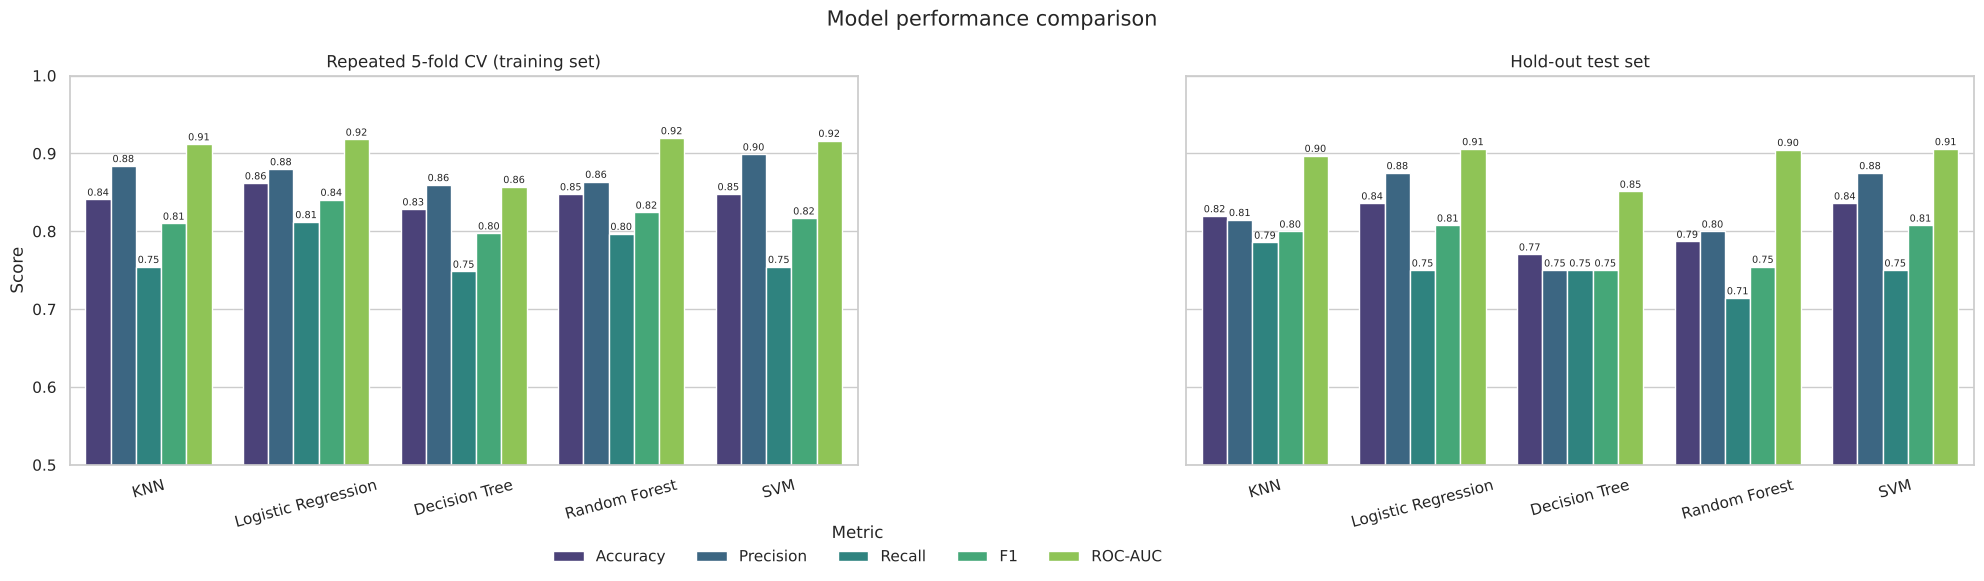

In [27]:
metric_cols = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
fig, axes = plt.subplots(1, 2, figsize=(20, 6), sharey=True)

# Left: repeated-CV means (training set); right: hold-out test set
cv_long = cv_table[metric_cols].reset_index().melt(id_vars="Model", var_name="Metric", value_name="Score")
sns.barplot(data=cv_long, x="Model", y="Score", hue="Metric", palette="viridis", ax=axes[0])
axes[0].set_title("Repeated 5-fold CV (training set)")

te_long = test_results[metric_cols].reset_index().melt(id_vars="Model", var_name="Metric", value_name="Score")
sns.barplot(data=te_long, x="Model", y="Score", hue="Metric", palette="viridis", ax=axes[1])
axes[1].set_title("Hold-out test set")

for ax in axes:
    ax.set_ylim(0.5, 1.0)
    ax.tick_params(axis="x", rotation=15)
    ax.set_xlabel("")
    for c in ax.containers:
        ax.bar_label(c, fmt="%.2f", fontsize=7, padding=1)
axes[1].legend_.remove()
axes[0].legend(title="Metric", loc="upper center", bbox_to_anchor=(1.0, -0.12), ncol=5, frameon=False)
plt.suptitle("Model performance comparison", fontsize=15)
plt.tight_layout()
save_fig("model_comparison.png")
plt.show()

### Choosing the best model with multiple criteria
For a screening-style task, picking the winner by accuracy alone is misleading:
- **Recall (sensitivity)** - a missed sick patient (false negative) is the costly error, so recall matters a lot.
- **Precision** - guards against flooding clinicians with false alarms.
- **F1** - the harmonic mean; it only rewards models that balance the two.
- **ROC-AUC** - threshold-free ranking quality, robust to the choice of cut-off.
- **Balanced accuracy** - the average of sensitivity and specificity, so neither class is ignored.
- **Stability (std of AUC across folds) and overfitting gap** - a model that scores well *consistently* and does not memorise the training data is more trustworthy.

Each model is ranked on six criteria (1 = best) using the cross-validated results, and the **lowest average rank wins**; ties are broken by ROC-AUC.

In [28]:
criteria = {                     # column -> True if higher is better
    "ROC-AUC": True, "F1": True, "Recall": True, "Balanced Acc": True,
    "ROC-AUC std": False, "Train-CV AUC gap": False}

rank_table = pd.DataFrame({c: cv_table[c].rank(ascending=not hi, method="min") for c, hi in criteria.items()})
rank_table["Average rank"] = rank_table.mean(axis=1)
rank_table = rank_table.join(cv_table["ROC-AUC"].rename("_auc")).sort_values(["Average rank", "_auc"], ascending=[True, False]).drop(columns="_auc")
display(rank_table.round(2))

best_name = rank_table.index[0]
bt, bc = test_results.loc[best_name], cv_table.loc[best_name]
runner_up = rank_table.index[1]

print("=" * 60)
print(f"BEST MODEL: {best_name}")
print("=" * 60)
print(f"Why: lowest average rank ({rank_table.loc[best_name, 'Average rank']:.2f}) across 6 criteria; "
      f"runner-up is {runner_up} ({rank_table.loc[runner_up, 'Average rank']:.2f}).")
print(f"Cross-validated : ROC-AUC {bc['ROC-AUC']:.3f} (+/- {bc['ROC-AUC std']:.3f}), F1 {bc['F1']:.3f}, "
      f"Recall {bc['Recall']:.3f}, Precision {bc['Precision']:.3f}, Accuracy {bc['Accuracy']:.3f}")
print(f"Hold-out test   : ROC-AUC {bt['ROC-AUC']:.3f}, F1 {bt['F1']:.3f}, Recall {bt['Recall']:.3f}, "
      f"Precision {bt['Precision']:.3f}, Accuracy {bt['Accuracy']:.3f}")
print(f"Train-CV AUC gap: {bc['Train-CV AUC gap']:.3f}")

top_acc = cv_table["Accuracy"].idxmax()
if top_acc != best_name:
    print(f"\nNote: {top_acc} has the highest CV accuracy ({cv_table.loc[top_acc, 'Accuracy']:.3f}), "
          f"but {best_name} was chosen because it is better on the combined criteria.")
else:
    print(f"\nNote: {best_name} also has the highest CV accuracy, so accuracy and the multi-criteria ranking agree.")

,ROC-AUC,F1,Recall,Balanced Acc,ROC-AUC std,Train-CV AUC gap,Average rank
Model,,,,,,,
Logistic Regression,2.0,1.0,1.0,1.0,2.0,2.0,1.50
Random Forest,1.0,2.0,2.0,2.0,1.0,3.0,1.83
SVM,3.0,3.0,3.0,3.0,3.0,1.0,2.67
KNN,4.0,4.0,3.0,4.0,4.0,5.0,4.00
Decision Tree,5.0,5.0,5.0,5.0,5.0,4.0,4.83


BEST MODEL: Logistic Regression
Why: lowest average rank (1.50) across 6 criteria; runner-up is Random Forest (1.83).
Cross-validated : ROC-AUC 0.918 (+/- 0.042), F1 0.841, Recall 0.812, Precision 0.880, Accuracy 0.862
Hold-out test   : ROC-AUC 0.906, F1 0.808, Recall 0.750, Precision 0.875, Accuracy 0.836
Train-CV AUC gap: 0.024

Note: Logistic Regression also has the highest CV accuracy, so accuracy and the multi-criteria ranking agree.


### Trade-offs between metrics
- **Accuracy vs recall:** accuracy treats both error types equally. Lowering the decision threshold would raise recall (fewer missed patients) at the cost of precision (more false alarms); ROC-AUC summarises this trade-off across all thresholds.
- **Precision vs recall:** F1 balances them, but the right balance is a clinical/cost decision, not a statistical one.
- **Model complexity vs interpretability:** Logistic Regression and a shallow Decision Tree are easy to explain; Random Forest and RBF-SVM are harder to interpret but often more flexible. When scores are within noise of each other, the simpler model is preferable.
- **Small-sample caveat:** with 302 unique patients, differences of one or two percentage points are within the cross-validation spread (see `ROC-AUC std`) and should not be over-interpreted.

### Save the final pipeline
The selected model's best hyper-parameters are kept, and the **complete pipeline (imputation + scaling + one-hot encoding + classifier)** is refitted on *all* 302 cleaned rows - the evaluation above is finished, so using the full data for the deployed model is legitimate and gives it slightly more to learn from. The reported metrics come from the train-only evaluation of the identical configuration; the saved metadata records this explicitly.

In [29]:
MODEL_DIR = Path("model")
MODEL_DIR.mkdir(exist_ok=True)

best_gs = tuned[best_name]
final_pipeline = clone(best_gs.best_estimator_).fit(X, y)      # preprocessing + model, one object

model_path = MODEL_DIR / "heart_disease_model.pkl"
joblib.dump(final_pipeline, model_path)

def _py(v):
    return v.item() if hasattr(v, "item") else v

metadata = {
    "project": "HeartGuard AI - Heart Disease Prediction",
    "model_name": best_name,
    "estimator": type(final_pipeline.named_steps["model"]).__name__,
    "model_version": "1.0.0",
    "training_date": dt.datetime.now().astimezone().isoformat(timespec="seconds"),
    "feature_names": FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "nominal_features": NOMINAL_FEATURES,
    "binary_features": BINARY_FEATURES,
    "target_name": TARGET,
    "target_definition": "HeartDisease = 1 when heart disease is present. Derived from heart.csv column 'target' "
                         "(where target==1 means NO disease in this file) via HeartDisease = 1 - target.",
    "target_labels": {str(k): v for k, v in TARGET_LABELS.items()},
    "best_params": {k.replace("model__", ""): _py(v) for k, v in best_gs.best_params_.items()},
    "data": {"rows_in_csv": int(len(df_raw)), "duplicate_rows_removed": int(len(df_raw) - len(df)),
             "rows_used": int(len(df)), "train_rows_for_evaluation": int(len(X_train)),
             "test_rows": int(len(X_test)), "final_model_fitted_on_rows": int(len(X)),
             "class_balance_disease_share": round(float(y.mean()), 4)},
    "metrics": {
        "note": "Hyper-parameters were tuned and metrics measured on the 80/20 split (final model refit on all rows).",
        "cross_validation_repeated_5fold_x3_train_set": {k: round(float(v), 4) for k, v in cv_table.loc[best_name].items()},
        "holdout_test_set": {k: (round(float(v), 4) if k in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "Specificity"] else int(v))
                             for k, v in test_results.loc[best_name].items()},
    },
    "comparison_all_models_cv": cv_table.round(4).reset_index().to_dict(orient="records"),
    "comparison_all_models_holdout": test_results[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].round(4).reset_index().to_dict(orient="records"),
    "library_versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                         "pandas": pd.__version__, "numpy": np.__version__, "joblib": joblib.__version__},
    "disclaimer": "Educational/demonstration model. Not a medical device and not a diagnostic tool.",
}
with open(MODEL_DIR / "model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Saved:", model_path, f"({model_path.stat().st_size / 1024:.1f} KB)")
print("Saved:", MODEL_DIR / "model_metadata.json")

Saved: model/heart_disease_model.pkl (4.9 KB)
Saved: model/model_metadata.json


In [30]:
# Verify: reload from disk and predict a raw (un-preprocessed) patient record
loaded = joblib.load(model_path)
sample = pd.DataFrame([{"age": 54, "sex": 1, "cp": 0, "trestbps": 130, "chol": 246, "fbs": 0,
                        "restecg": 1, "thalach": 150, "exang": 1, "oldpeak": 1.5, "slope": 1,
                        "ca": 1, "thal": 3}])[FEATURES].astype(float)
p = loaded.predict_proba(sample)[0, 1]
print(f"Reloaded pipeline steps: {[n for n, _ in loaded.steps]}")
print(f"P(heart disease) for the sample patient: {p:.3f} -> {TARGET_LABELS[int(loaded.predict(sample)[0])]}")

# Reloaded model must reproduce the in-memory model exactly
assert np.allclose(loaded.predict_proba(X), final_pipeline.predict_proba(X))
print("Reloaded pipeline reproduces the in-memory pipeline exactly: OK")

Reloaded pipeline steps: ['preprocess', 'model']
P(heart disease) for the sample patient: 0.934 -> Heart disease (higher likelihood)
Reloaded pipeline reproduces the in-memory pipeline exactly: OK


## Summary
- Tasks 1-7 are complete and run top-to-bottom; the results are reproducible (`random_state` fixed everywhere).
- Data issues found and handled: 723 duplicate rows removed (leakage), placeholder codes (`ca == 4`, `thal == 0`) imputed, and the **inverted target encoding** corrected through the derived `HeartDisease` label.
- Preprocessing is learned only on training data inside the pipeline; the saved `model/heart_disease_model.pkl` contains the full pipeline used by `app.py`.